# Filbin et al. 2018 — Pediatric H3-K27M Glioma (DMG)
## 01 · Preprocessing, integration & manifold scoping

Malignant cells (SmartSeq2, TPM). Goal: an integrated, continuous manifold on which to fit the
cell-state trajectory. **Gate 1** is judged *visually* on the regenerated embedding — is the
malignant structure sample-mixed and continuous? A proliferating (cycling) compartment is a
trajectory confound (03_eval lobe-identity rule): it is identified here and **scoped out** so the
developmental fork resolves, then the fork is **re-embedded** and judged visually as a clean fork.

In [ ]:
import os, sys, re, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # e.g. Filbin2018_Brain-9  (attempt suffix)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Brain)
dset = re.sub(r'-\d+$', '', name)                       # strip -N attempt suffix -> input folder key
pth  = os.path.join(*([os.pardir] * 6))                 # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)                       # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)   # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
FEAT = os.path.join(pth_data, 'features', 'biomart')
print('dataset:', name, '| category:', cat)

dataset: Filbin2018_Brain-9 | category: Brain


### Load malignant cells + published metadata
`load.py` auto-detects TPM (pass-through) and `log1p`s. Filbin's published per-cell cell-cycle
phase and OPC/AC/OC lineage scores (`Cells.csv`) are attached for annotation and confound checks.

In [ ]:
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
cells = pd.read_csv(os.path.join(pth_in, 'Cells.csv'), index_col=0)
for c in ['g1s_score', 'g2m_score', 'cell_cycle_phase', 'opc_like', 'ac_like', 'oc_like', 'mp_top']:
    adata.obs[c] = cells.loc[adata.obs_names, c].values
for c in ['g1s_score', 'g2m_score', 'opc_like', 'ac_like', 'oc_like']:
    adata.obs[c] = adata.obs[c].astype(float)
print('malignant:', adata.shape, '| Xmax %.2f (TPM, log1p)' % adata.X.max())
print('per-sample malignant counts:'); print(adata.obs['sample'].value_counts().to_string())

Loading ../../../../../../data/unzip/CCCA/Data_Filbin2018_Brain
Done.
malignant: (2259, 23686) | Xmax 12.36 (TPM, log1p)
per-sample malignant counts:
sample
MUV05      667
BCH869     489
BCH836     438
MUV10      283
BCH1126    241
MUV01      141


### Sample threshold
Read the per-sample counts for a clean gap. Filbin's counts (667 to 141) are smooth (max adjacent
ratio 1.7 < 2), so there is **no clean count gap**: the >=100 floor keeps all 6 malignant samples.

In [ ]:
n = adata.obs['sample'].value_counts()
ratios = (n.values[:-1] / n.values[1:]).round(2)
print('descending counts:', n.values.tolist()); print('adjacent ratios:', ratios.tolist())
keep = n.index[n >= 100]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('kept %d/%d samples (>=100) -> %d cells' % (len(keep), n.size, adata.n_obs))

descending counts: [667, 489, 438, 283, 241, 141]
adjacent ratios: [1.36, 1.12, 1.55, 1.17, 1.71]
kept 6/6 samples (>=100) -> 2259 cells


### Gene filter -> overdispersed selection -> PCA -> Harmony integration on `sample`

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
sce.pp.harmony_integrate(adata, 'sample', theta=10, max_iter_harmony=20)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3779 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3779


### Neighbors -> UMAP -> Leiden
`n_pcs=20` (bounded to the Puram-40 / Kuerten-20 precedent; scree elbow under-powers small
SmartSeq2 sets). No `sc.pp.scale` (absent from the reference protocol; it fragments the manifold).

In [ ]:
sc.pp.neighbors(adata, n_pcs=20, n_neighbors=30, use_rep='X_pca_harmony')
sc.tl.umap(adata, spread=1.3, random_state=SEED)
sc.tl.leiden(adata, resolution=1.0, random_state=SEED)
print('leiden clusters:', adata.obs.leiden.nunique())

leiden clusters: 10


### Gate 1 (part 1) — mixing & continuity, judged on the embedding
Samples intermix across one connected body (no per-patient archipelago); the **cycling compartment
is visually obvious** as a coherent lobe (high g2m/g1s, `cell_cycle_phase` cycling).

connected components (kNN): 1 | samples intermixed: 6


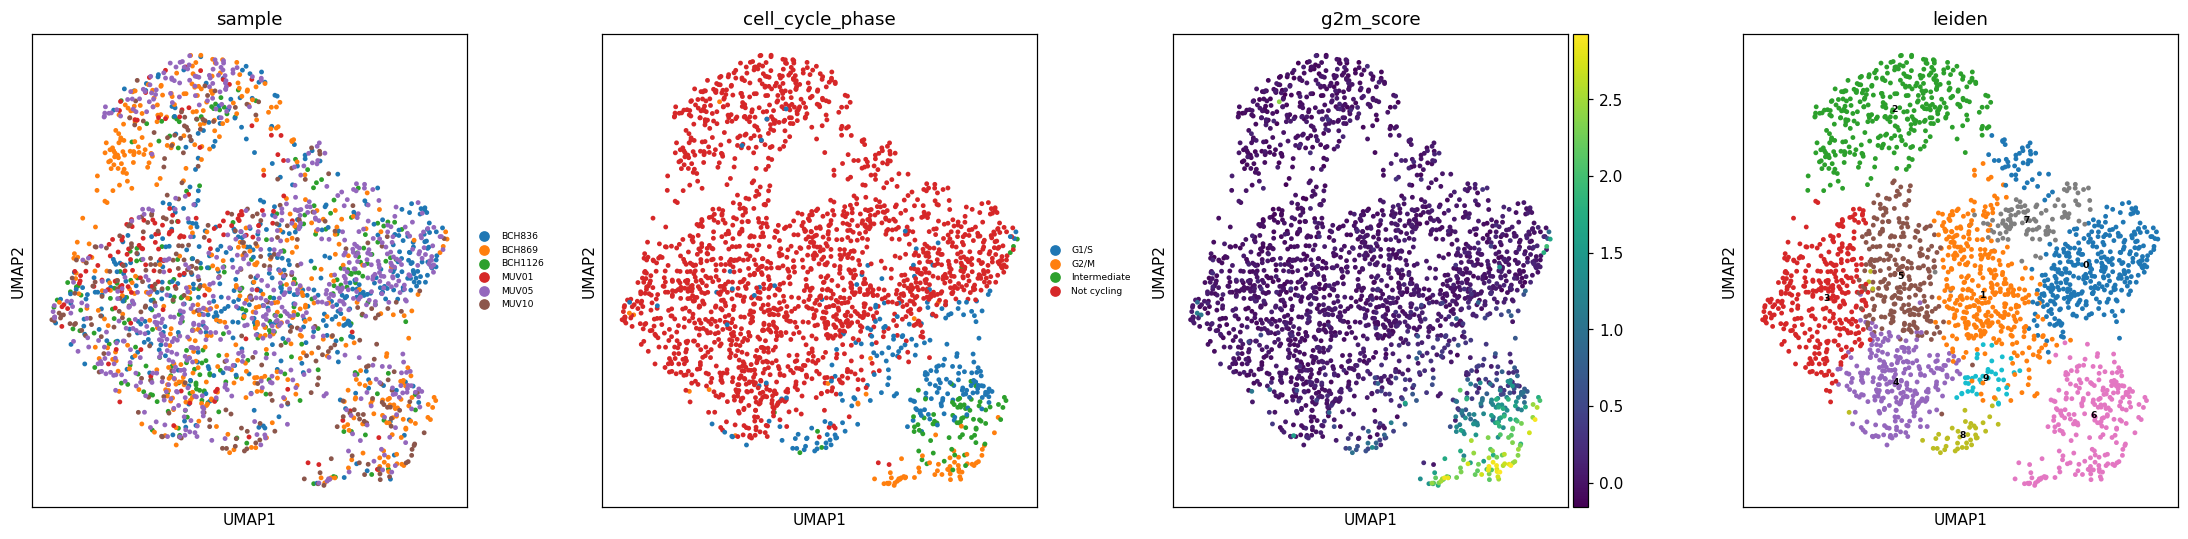

In [ ]:
adata.obs['cycling'] = adata.obs.cell_cycle_phase.isin(['G1/S', 'G2/M', 'Intermediate'])
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for ax, c in zip(axs, ['sample', 'cell_cycle_phase', 'g2m_score', 'leiden']):
    sc.pl.umap(adata, color=c, ax=ax, show=False, size=40,
               cmap='viridis' if c == 'g2m_score' else None,
               legend_loc='on data' if c == 'leiden' else 'right margin', legend_fontsize=6)
    ax.set_title(c)
plt.tight_layout(); plt.show()
from scipy.sparse.csgraph import connected_components
ncomp, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('connected components (kNN):', ncomp, '| samples intermixed:', adata.obs['sample'].nunique())

### Identify & scope out the cycling lobe
Per-Leiden cycling fraction: the cycling lobe is the set of clusters that are **majority cycling**
(>50%). These proliferating cells confound pseudotime; they are removed so the developmental fork
resolves (03_eval fork-2 lobe-identity rule). Cell cycle is otherwise orthogonal to the embryonic
modules (verified in 03), so this removes a confound, not developmental signal.

In [ ]:
cyc_frac = adata.obs.groupby('leiden', observed=True)['cycling'].mean().sort_values(ascending=False)
print('per-leiden cycling fraction:'); print(cyc_frac.round(3).to_string())
cyc_lobes = cyc_frac.index[cyc_frac > 0.5].tolist()
print('cycling lobe clusters (>50% cycling):', cyc_lobes)
adata.obs['compartment'] = np.where(adata.obs.leiden.isin(cyc_lobes), 'Cycling', 'Developmental')
print(adata.obs.compartment.value_counts().to_dict())
fork = adata[adata.obs.compartment == 'Developmental'].copy()
print('scoped developmental fork:', fork.n_obs, 'cells (removed', adata.n_obs - fork.n_obs, 'cycling)')

per-leiden cycling fraction:
leiden
6    0.986
8    0.805
9    0.158
1    0.149
0    0.102
4    0.057
5    0.020
3    0.019
2    0.014
7    0.010
cycling lobe clusters (>50% cycling): ['6', '8']
{'Developmental': 1998, 'Cycling': 261}
scoped developmental fork: 1998 cells (removed 261 cycling)


### Re-embed the fork (branching -> 2-D, so re-embedding is safe)
The fork is a 2-D branching compartment (not a 1-D strip), so re-embedding will not fold it (the
Kuerten section-4 fold risk applies to *linear* compartments). Re-embed on the integrated PCs and
confirm **visually** that it resolves into a clean fork: a progenitor body with two arms.

re-embedded fork: (1998, 21224)


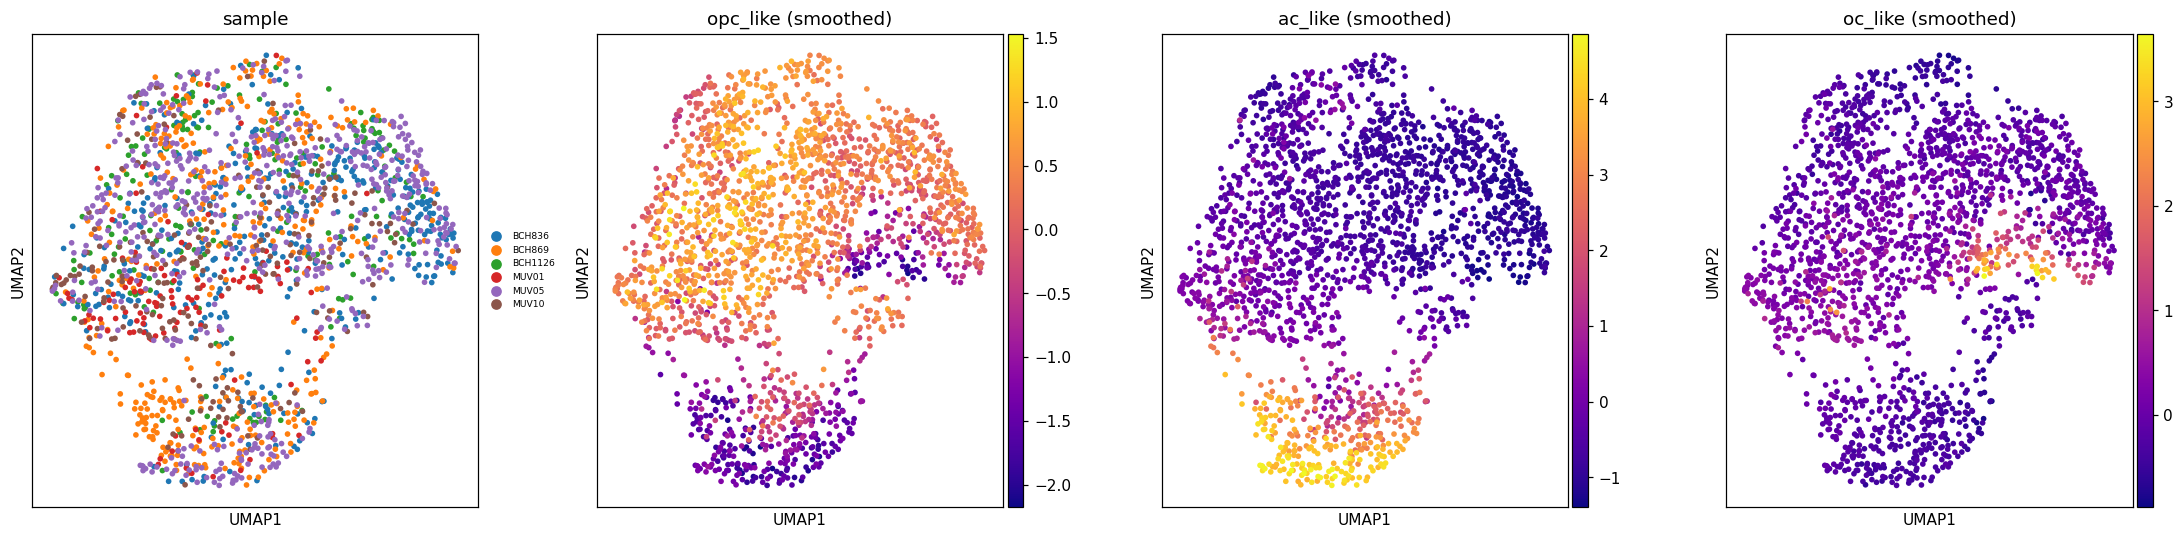

In [ ]:
sc.pp.neighbors(fork, n_pcs=20, n_neighbors=30, use_rep='X_pca_harmony')
sc.tl.umap(fork, spread=1.3, random_state=SEED)
A = fork.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel(); deg[deg == 0] = 1
for k in ['opc_like', 'ac_like', 'oc_like']:
    fork.obs[k + '_sm'] = (A @ fork.obs[k].values) / deg
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for ax, c in zip(axs, ['sample', 'opc_like_sm', 'ac_like_sm', 'oc_like_sm']):
    sc.pl.umap(fork, color=c, ax=ax, show=False, size=55,
               cmap=None if c == 'sample' else 'plasma', legend_fontsize=6)
    ax.set_title(c.replace('_sm', ' (smoothed)'))
plt.tight_layout(); plt.show()
print('re-embedded fork:', fork.shape)

### Annotate subtypes — data markers + Filbin published states
Cluster the fork (Leiden res=0.4). Assign roles by **module-convergence** and **lineage argmax**:
the cluster with maximal Gast+pSom co-expression is the **Mixed** convergence hub (Puram's "Mixed"
analog); the others are the **OPC-like / AC-like / OC-like** states (Filbin 2018, *Science* 360:331).
Annotation uses both data-derived module scores and the publication's lineage calls.

In [ ]:
sc.tl.leiden(fork, resolution=0.4, random_state=SEED, key_added='lz')
fd = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
      for f in sorted(glob.glob(os.path.join(FEAT, '*.csv')))}
gref = fd['union'][fd['union'].isin(fork.var_names)]
for src, s in fd.items():
    if src == 'union': continue
    g = s[s.isin(fork.var_names)]
    sc.tl.score_genes(fork, gene_list=g, score_name=src, ctrl_as_ref=False, gene_pool=gref, random_state=1234)
fork.obs['Gast'] = fork.obs.GSE162534; fork.obs['pSom'] = fork.obs.GSE229103; fork.obs['Crest'] = fork.obs.rRNAModifications
prof = fork.obs.groupby('lz', observed=True).agg(
    n=('lz', 'size'), Gast=('Gast', 'mean'), pSom=('pSom', 'mean'),
    opc=('opc_like', 'mean'), ac=('ac_like', 'mean'), oc=('oc_like', 'mean'))
prof['joint'] = prof.Gast + prof.pSom
print(prof.round(3).to_string())
hub = prof.joint.idxmax()
lab = {}
for lz in prof.index:
    if lz == hub:
        lab[lz] = 'Mixed'
    else:
        lin = prof.loc[lz, ['opc', 'ac', 'oc']].astype(float).idxmax()
        lab[lz] = {'opc': 'OPC-like', 'ac': 'AC-like', 'oc': 'OC-like'}[lin]
fork.obs['celltype'] = pd.Categorical(fork.obs.lz.map(lab))
print('hub (Mixed) cluster =', hub, '| celltype:', fork.obs.celltype.value_counts().to_dict())

      n   Gast   pSom    opc     ac     oc  joint
lz                                               
0   761  0.043  0.235  0.423 -0.176  0.079  0.278
1   488  0.031  0.236  0.206 -0.802  0.216  0.266
2   399 -0.073  0.145  0.024 -0.954  0.114  0.072
3   350  0.047  0.213 -1.181  3.033 -0.319  0.259
hub (Mixed) cluster = 0 | celltype: {'OC-like': 887, 'Mixed': 761, 'AC-like': 350}


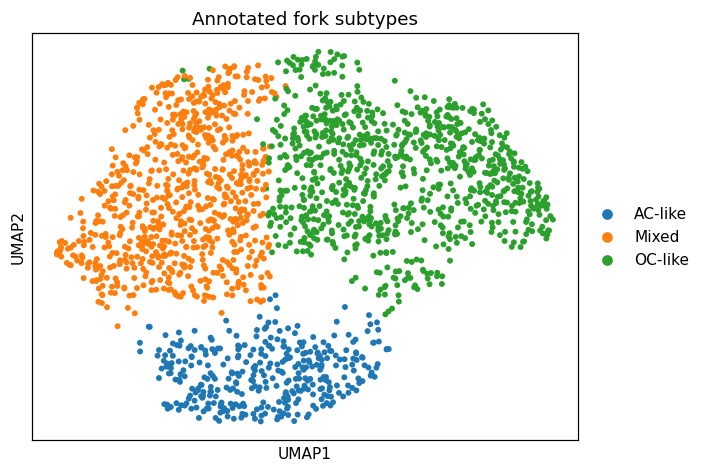

In [ ]:
sc.pl.umap(fork, color='celltype', size=60, title='Annotated fork subtypes'); plt.show()

### Save processed manifold (scoped, re-embedded, annotated)

In [ ]:
fork.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', fork.shape)

saved processed.h5ad (1998, 21224)


### `samples.pdf` — sample integration on the analysis manifold (Gate 1 evidence)

saved samples.pdf


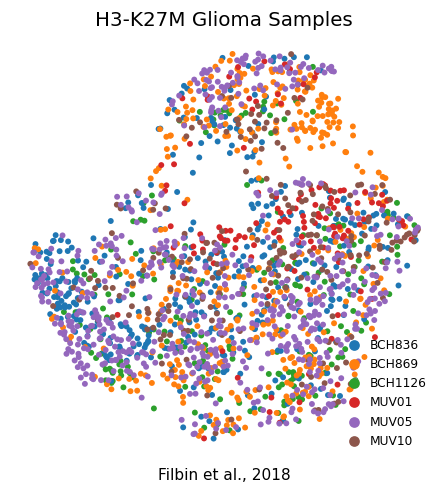

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(fork, color='sample', size=60, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='lower right', columnspacing=.5, handletextpad=.25, fontsize=8)
ax.set_title('H3-K27M Glioma Samples', size=13)
ax.text(.5, -.05, 'Filbin et al., 2018', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved samples.pdf')